# Multi-Factor Equity Screener

By Sawyer Cross. Source code: [github.com/FleximusRex/Finance-equity-scanner](https://github.com/FleximusRex/Finance-equity-scanner)

This notebook ranks US stocks on five factor categories (value, quality, momentum, growth and low volatility), then backtests the price-based factors to see whether they predicted returns. My result: they did not.

**How to use it**

1. Click **Runtime > Run all** (in Jupyter: **Run > Run All Cells**).
2. Wait a few minutes. The first run downloads prices and fundamentals from Yahoo Finance.
3. Scroll down. Each step has a short explanation under it.

To try something else, change the two settings in step 2: the stock universe and the ticker for the single-stock report.

**Read this first.** Fundamentals from Yahoo are current values, not point-in-time (point-in-time means the value an investor could actually have seen on that date), so the historical backtest uses only price factors: 12-1 momentum, 6-month momentum, 60-day volatility and beta. The stock lists are today's index members, which builds in survivorship bias: companies that failed or were dropped are missing, so every portfolio looks better than it would have in real time. This is a research project, not investment advice.

The numbers below come from a fresh download when the notebook was last run. Yahoo revises its data, so they can differ in the last digit from the saved tables in `outputs/`. Those tables are the reference. Running this notebook does not overwrite them.

## 1. Set up

This cell gets the code and installs what is missing. In Colab it installs `yfinance` at the version pinned in `requirements.txt`, so Colab and a local run use the same downloader. Everything else is already in Colab, so you will not be asked to restart the runtime.

In [1]:
#@title Set up (runs automatically) { display-mode: "form" }
import importlib.util
import os
import shutil
import subprocess
import sys

REPO_URL = "https://github.com/FleximusRex/Finance-equity-scanner.git"

if "google.colab" in sys.modules:
    # Start from a fresh copy every time, so an older copy in this runtime cannot interfere.
    os.chdir("/content")
    shutil.rmtree("Finance-equity-scanner", ignore_errors=True)
    subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("Finance-equity-scanner")
    # Colab already has pandas, numpy, scipy, matplotlib, plotly and pyarrow, and replacing
    # those would force a restart. Only yfinance is always installed, at the pinned version.
    with open("requirements.txt") as f:
        pinned = dict(line.strip().split("==") for line in f if "==" in line)
    wanted = [f"yfinance=={pinned['yfinance']}"]
    for name in ("lxml", "statsmodels", "openpyxl"):
        if importlib.util.find_spec(name) is None:
            wanted.append(f"{name}=={pinned[name]}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *wanted], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # running locally: start from the repo root
for name in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[name]  # forget any older copy of the code imported earlier
sys.path.insert(0, os.getcwd())
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True)
print("Ready. Code version:", commit.stdout.strip() or "unknown")

Ready. Code version: 1b852a5


## 2. Choose your settings

| Universe | What it is | Rough runtime on a fresh Colab runtime |
|---|---|---|
| `test50` | 50 large caps I picked across sectors | about 1 minute |
| `sp100` (default) | The S&P 100, the 100 largest blue-chip US companies | 2 to 3 minutes |
| `sp500` | The full S&P 500 | 10 to 15 minutes, and Yahoo may rate-limit the download |

If Yahoo rate-limits a run, wait a few minutes and run all again. The cache keeps what was already downloaded.

In [2]:
UNIVERSE = "sp100"  #@param ["test50", "sp100", "sp500"]
TICKER = "AAPL"  #@param {type:"string"}

In [3]:
import io
import logging
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

from src import backtest, config, french, rank, visualization
from src.data_loader import load_prices
from src.excel_export import write_workbook
from src.ff_regression import ff_regression
from src.report import show_report, stock_report
from src.run_info import load_run_info
from src.universe import get_universe

config.set_universe(UNIVERSE)
saved = load_run_info()  # as-of date of the committed tables in outputs/<universe>/
NOTEBOOK_DIR = config.CACHE_DIR / "notebook"  # keep the saved outputs untouched
config.CHARTS_DIR = NOTEBOOK_DIR / "charts"

logging.basicConfig(level=logging.INFO, format="%(message)s")
logging.getLogger("yfinance").setLevel(logging.CRITICAL)
logging.getLogger("src.visualization").setLevel(logging.WARNING)

prices = load_prices([*get_universe(), config.BENCHMARK])
AS_OF = f"{prices.index[-1]:%Y-%m-%d}"
print(f"Universe: {UNIVERSE} ({len(get_universe())} stocks). Prices through {AS_OF}.")
print(f"Saved tables in outputs/{UNIVERSE}/ are as of {saved.get('as_of', 'n/a')} (run_info.json).")

Universe: sp100 (101 stocks). Prices through 2026-11-16.
Saved tables in outputs/sp100/ are as of 2026-11-16 (run_info.json).


## 3. Today's ranking

Every stock gets a score from 12 metrics in five categories. Each metric is winsorized (extreme values clipped), converted to a cross-sectional z-score (how many standard deviations the stock sits above or below the average stock on that date), and averaged within its category. The composite is a weighted average of the category scores.

- **Composite**: higher is better. A score of 1 means about one standard deviation above the average stock.
- **Quintile**: 1 is the best 20% of stocks, 5 is the worst 20%.
- **Momentum and LowVol** are category scores. A negative LowVol means the stock is more volatile than average.

In [4]:
rankings = rank.build_rankings(prices=prices)
columns = ["Ticker", "Company", "Sector", "Composite", "Quintile", "Value", "Quality",
           "Momentum", "Growth", "LowVol"]
display(rankings[columns].head(10).round(2).reset_index(drop=True))

,Ticker,Company,Sector,Composite,Quintile,Value,Quality,Momentum,Growth,LowVol
0,SNDK,Sandisk Corporation,Technology,1.88,1,1.75,1.79,1.23,6.60,-3.03
1,MU,"Micron Technology, Inc.",Technology,1.57,1,0.85,1.24,2.38,4.63,-2.45
2,ABBV,AbbVie Inc.,Healthcare,0.92,1,-0.30,0.91,0.96,2.95,0.85
3,COP,ConocoPhillips,Energy,0.46,1,0.76,0.03,0.64,0.13,0.82
4,CMCSA,Comcast Corporation,Communication Services,0.45,1,2.12,0.10,-0.36,-0.39,0.50
5,MO,"Altria Group, Inc.",Consumer Defensive,0.45,1,0.49,0.86,0.25,-0.30,1.01
6,MA,Mastercard Incorporated,Financial Services,0.40,1,-0.32,1.28,0.52,-0.18,0.61
7,CVX,Chevron Corporation,Energy,0.39,1,0.62,-0.02,0.42,0.23,1.00
8,LLY,Eli Lilly and Company,Healthcare,0.38,1,-0.62,0.98,1.00,0.04,0.40
9,V,Visa Inc.,Financial Services,0.35,1,-0.33,1.07,0.54,-0.19,0.62


The top of a ranking like this is often dominated by stocks with extreme recent momentum. Treat it as a screen for further research, not a list of recommendations.

## 4. Did the factors predict returns?

Each month-end I ranked every stock using only data available at that date, split them into five equal groups, and held each group for the next month. Q1 is the top-ranked group. Costs are 10 bps (0.10%) per side, charged on turnover, which is the share of the portfolio that is traded at each rebalance.

The backtest uses only the price factors (momentum and low volatility), for the reason in the note at the top. It stops at the last complete month, so a few trading days at the end of the data are never counted as a full month.

The Sharpe ratio here uses excess returns: the portfolio's return minus the 1-month T-bill rate, which is what the same money would have earned risk-free. The T-bill rate comes from Kenneth French's data library.

In [5]:
dates = backtest.rebalance_dates(prices.index)[:-1]
signals = backtest.signals_through_time(prices, dates)
monthly, ic = backtest.backtest_signal(prices, signals["composite"])
monthly["RF"] = french.risk_free(monthly.index)
table, ic_summary = backtest.summarize(monthly, ic)

portfolios = {"Top 20% (Q1)": "Q1_net", "Bottom 20% (Q5)": "Q5_net",
              "Long-short (Q1 minus Q5)": "LS_net", "Equal-weight universe": "EW_net",
              "SPY": "SPY"}
results = pd.DataFrame({
    name: {"Return per year": f"{table.loc[key, 'CAGR']:.1%}",
           "Sharpe ratio (excess return)": f"{table.loc[key, 'Sharpe']:.2f}",
           "Worst drawdown": f"{table.loc[key, 'MaxDD']:.1%}"}
    for name, key in portfolios.items()}).T
print(f"{len(monthly)} holding months, {monthly.index[0]:%b %Y} to {monthly.index[-1]:%b %Y}. "
      f"Average T-bill rate: {monthly['RF'].mean() * 12:.1%} a year.")
display(results)

French RF does not cover 1 month(s) yet; using ^IRX


142 holding months, Jan 2015 to Oct 2026. Average T-bill rate: 2.0% a year.


,Return per year,Sharpe ratio (excess return),Worst drawdown
Top 20% (Q1),21.7%,1.17,-21.9%
Bottom 20% (Q5),19.0%,0.81,-33.9%
Long-short (Q1 minus Q5),-1.9%,-0.00,-47.2%
Equal-weight universe,18.7%,1.08,-22.4%
SPY,13.5%,0.79,-23.9%


How to read this: compare **Q1** with the **equal-weight universe**, not with SPY. Both hold today's index members, so both benefit from survivorship bias, and the equal-weight basket needs no factor model at all. If Q1 is not clearly better than that basket, the factors added little. The long-short row is the pure factor bet: buy Q1 and short Q5, so the market's own return cancels out. Its return per year is the quintile spread.

In [6]:
names = {"mom_12_1": "12-1 month momentum", "ret_6m": "6-month momentum",
         "vol_60d": "60-day volatility (low is better)", "beta": "Beta (low is better)",
         "composite": "Composite (momentum + low vol)"}
tests = backtest.factor_tests(prices, signals)
verdict = pd.DataFrame({
    "Average rank IC": tests["IC_mean"].round(3),
    "t-stat": tests["IC_t"].round(2),
    "p-value": tests["IC_p"].round(3),
    "Holm p-value": tests["IC_p_holm"].round(3),
    "Significant at 5%?": ["yes" if p < 0.05 else "no" for p in tests["IC_p_holm"]],
}).rename(index=names)
display(verdict)
best = tests["IC_p_holm"].min()
print(f"Smallest Holm-adjusted p-value: {best:.3f}. "
      + ("At least one factor is significant at 5%." if best < 0.05
         else "No factor is significant at the 5% level."))

,Average rank IC,t-stat,p-value,Holm p-value,Significant at 5%?
factor,,,,,
12-1 month momentum,0.008,0.40,0.687,1.000,no
6-month momentum,0.019,1.02,0.308,0.923,no
60-day volatility (low is better),-0.046,-2.03,0.044,0.219,no
Beta (low is better),-0.052,-1.95,0.053,0.219,no
Composite (momentum + low vol),-0.001,-0.04,0.972,1.000,no


Smallest Holm-adjusted p-value: 0.219. No factor is significant at the 5% level.


**What the columns mean.** The rank IC (information coefficient) is the correlation between a factor's ranking of the stocks and the ranking of their returns over the next month, measured each month and averaged. An IC of 0 means no predictive power. The t-stat and p-value test whether the average IC is really different from zero. A p-value below 0.05 is the usual bar.

I tested five signals, and the more signals you test, the more likely one clears that bar by luck. The Holm p-value corrects for this, and it is the one to judge by.

Low volatility showed a negative IC, the wrong sign: riskier stocks did better over this period. That fits a long bull market, and survivorship bias inflates it.

## 5. Is the result just known factors? The Fama-French regression

A portfolio can beat the market simply because it leans toward kinds of stocks that are already known to earn more, such as small, cheap or rising ones. The Fama-French regression checks for this. It explains each portfolio's monthly excess return with six well-known factor returns:

- **Mkt-RF**: the stock market minus the T-bill rate
- **SMB**: small stocks minus big stocks (size)
- **HML**: cheap stocks minus expensive stocks (value)
- **RMW**: profitable companies minus unprofitable ones (profitability)
- **CMA**: companies that invest conservatively minus those that invest aggressively
- **UMD**: recent winners minus recent losers (momentum)

The loadings say how much the portfolio moves with each factor. The Fama-French alpha is the return per year that is left over after those exposures are accounted for. The t-stat uses Newey-West standard errors, which stay valid when monthly returns are autocorrelated or change in volatility. An alpha with a t-stat below about 2 cannot be told apart from zero.

The French files are published a month or two late, so the regression uses only the months both datasets cover.

In [7]:
ff = ff_regression(monthly, french.load_factors())
labels = {"Q1": "Top 20% (Q1)", "LS": "Long-short (Q1 minus Q5)", "EW": "Equal-weight universe"}
ff_view = pd.DataFrame({
    "Alpha per year": ff["Alpha_ann"].map("{:.1%}".format),
    "Alpha t-stat": ff["Alpha_t"].round(2),
    **{c: ff[c].round(2) for c in french.FACTOR_COLS},
    "R2": ff["R2"].round(2),
}).rename(index=labels)
first, last = pd.Timestamp(ff["First"].iloc[0]), pd.Timestamp(ff["Last"].iloc[0])
print(f"{ff['Months'].iloc[0]} months, {first:%b %Y} to {last:%b %Y}")
display(ff_view)

for key, label in labels.items():
    row = ff.loc[key]
    reading = ("different from zero" if abs(row["Alpha_t"]) > 1.96
               else "not statistically different from zero")
    print(f"{label}: alpha of {row['Alpha_ann']:.1%} a year (t = {row['Alpha_t']:.2f}), {reading}.")

141 months, Jan 2015 to Sep 2026


,Alpha per year,Alpha t-stat,Mkt-RF,SMB,HML,RMW,CMA,UMD,R2
Portfolio,,,,,,,,,
Top 20% (Q1),6.2%,3.03,1.00,0.02,0.08,-0.04,0.02,0.48,0.81
Long-short (Q1 minus Q5),-2.6%,-0.75,-0.04,0.32,-0.01,0.31,0.17,1.19,0.67
Equal-weight universe,4.7%,8.26,0.97,-0.09,0.09,-0.01,0.05,-0.05,0.96


Top 20% (Q1): alpha of 6.2% a year (t = 3.03), different from zero.
Long-short (Q1 minus Q5): alpha of -2.6% a year (t = -0.75), not statistically different from zero.
Equal-weight universe: alpha of 4.7% a year (t = 8.26), different from zero.


**How to read it.** Look at the equal-weight universe first. It holds every stock in the list with no selection at all, so it has no skill, and any alpha it shows is survivorship bias: the list was chosen with hindsight. That row is the baseline. Q1's alpha only means something to the extent that it is larger than the equal-weight alpha.

The long-short row removes that bias, because Q1 and Q5 are both drawn from the same list of survivors. If its alpha is not statistically different from zero, the factor ranking added nothing beyond exposures an investor could already buy cheaply. The loadings show what the ranking really did: a positive UMD loading means Q1 bought recent winners, a positive RMW loading means it leaned toward profitable companies, and a Mkt-RF loading below 1 means it held calmer stocks than the market.

## 6. Robustness checks

A backtest result should not depend on one convenient assumption. This table reruns the same backtest with different trading costs, in three separate periods, and with every trade delayed by one day (the signal uses the month-end close and the trade happens at the next day's close).

In [8]:
robust = backtest.robustness_table(prices, signals["composite"], monthly["RF"])
robust_view = pd.DataFrame({
    "Q1 return per year": robust["Q1_CAGR"].map("{:.1%}".format),
    "Q1 Sharpe": robust["Q1_Sharpe"].round(2),
    "Long-short return per year": robust["LS_CAGR"].map("{:.1%}".format),
    "Long-short Sharpe": robust["LS_Sharpe"].round(2),
    "Equal-weight return per year": robust["EW_CAGR"].map("{:.1%}".format),
    "Equal-weight Sharpe": robust["EW_Sharpe"].round(2),
    "Months": robust["Months"],
})
display(robust_view)

,Q1 return per year,Q1 Sharpe,Long-short return per year,Long-short Sharpe,Equal-weight return per year,Equal-weight Sharpe,Months
Case,,,,,,,
Cost 0 bps per side,22.4%,1.21,-0.7%,0.06,18.7%,1.08,142
Cost 10 bps per side,21.7%,1.17,-1.9%,-0.00,18.7%,1.08,142
Cost 25 bps per side,20.6%,1.11,-3.7%,-0.09,18.5%,1.07,142
Cost 50 bps per side,18.7%,1.02,-6.6%,-0.25,18.3%,1.06,142
Sub-period 2015-2019,19.7%,1.40,-1.5%,-0.02,17.0%,1.23,60
Sub-period 2020-2022,13.5%,0.67,2.3%,0.21,12.1%,0.61,36
Sub-period 2023-latest,31.4%,1.51,-5.7%,-0.15,26.3%,1.63,46
One-day execution lag,20.8%,1.10,-3.1%,-0.06,18.7%,1.05,142


What to look for: whether Q1 stays ahead of the equal-weight universe in every row, and whether the long-short return keeps the same sign across the three periods. A factor that only works in one period, or only with zero costs, is not a finding.

## 7. Charts

The images are shrunk here to keep the notebook light. Full-size charts for each universe are in `outputs/<universe>/charts/` in the repository.

**The 20 highest composite scores.**

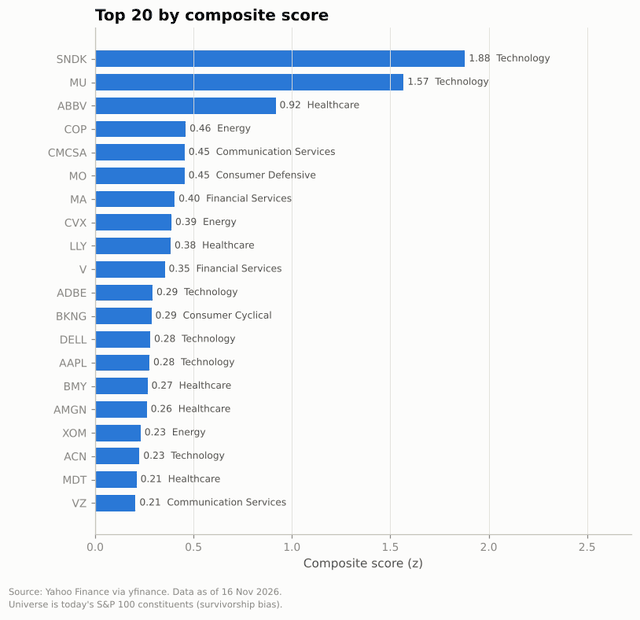

**Category scores for those 20 stocks. Blue is strong, red is weak.**

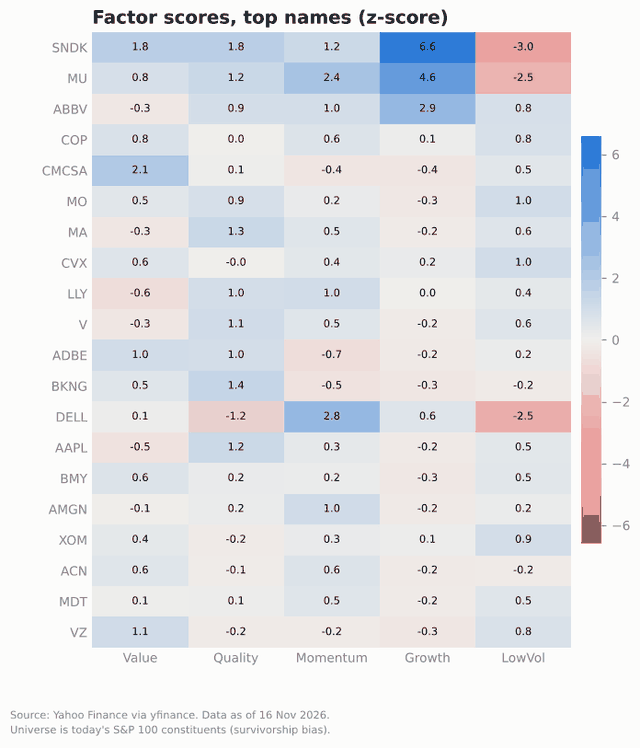

**Growth of $1 in each quintile portfolio, after costs.**

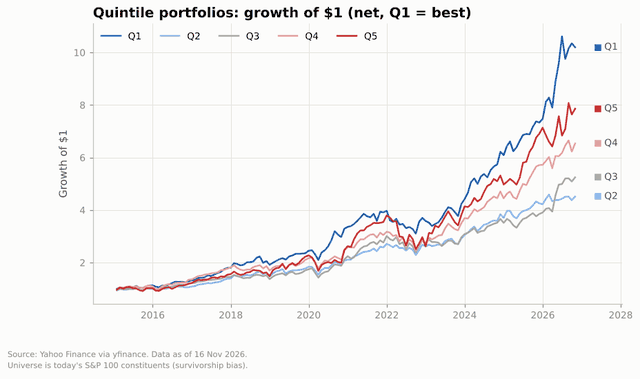

**Q1, the long-short portfolio, the equal-weight universe and SPY, with drawdowns below.**

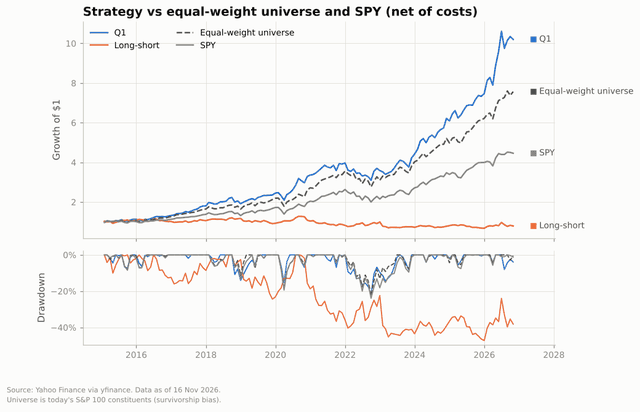

**Rolling 12-month Sharpe ratio. It swings a lot, which is a reason for caution.**

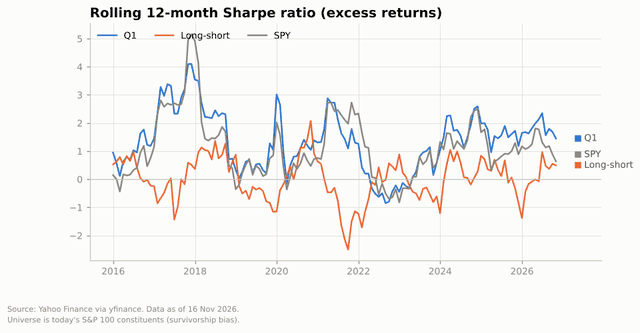

**Monthly rank IC. Bars above zero mean the ranking worked that month. Mean IC is near zero.**

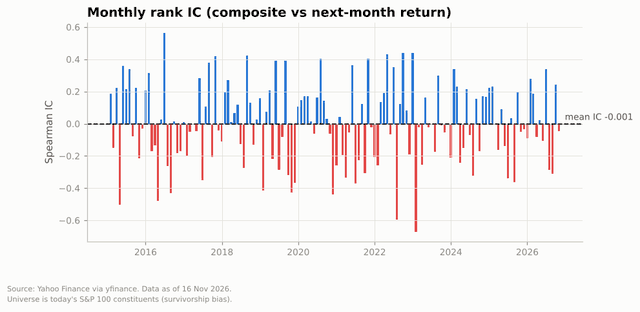

**Where the top quintile is concentrated by sector, against the whole universe.**

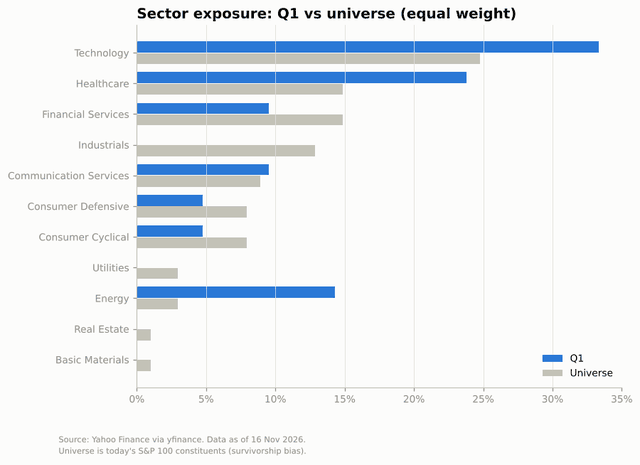

In [9]:
def show_small(path, width=640):
    image = PILImage.open(path).convert("RGB")
    image = image.resize((width, round(image.height * width / image.width)), PILImage.LANCZOS)
    buffer = io.BytesIO()
    image.quantize(128).save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


captions = {
    "01": "The 20 highest composite scores.",
    "02": "Category scores for those 20 stocks. Blue is strong, red is weak.",
    "03": "Growth of $1 in each quintile portfolio, after costs.",
    "04": "Q1, the long-short portfolio, the equal-weight universe and SPY, with drawdowns below.",
    "05": "Rolling 12-month Sharpe ratio. It swings a lot, which is a reason for caution.",
    "06": "Monthly rank IC. Bars above zero mean the ranking worked that month. Mean IC is near zero.",
    "07": "Where the top quintile is concentrated by sector, against the whole universe.",
}
for path in visualization.make_all(rankings, monthly.assign(IC=ic), asof=AS_OF):
    display(Markdown(f"**{captions[path.name[:2]]}**"))
    show_small(path)

## 8. Look up one stock

Change `TICKER` in step 2 and rerun this cell. The ticker must be in the universe you chose. The two interactive charts show in Colab and Jupyter but not in GitHub's notebook preview.

In [10]:
try:
    show_report(stock_report(TICKER.upper(), rankings=rankings, prices=prices))
except ValueError:
    print(f"{TICKER} is not in the {UNIVERSE} universe. Pick another ticker or switch the universe.")

AAPL - Apple Inc. (Technology)
Composite +0.28 | percentile 87 | quintile 1 | sector rank 5/25
Category z-scores: Value -0.49  Quality +1.20  Momentum +0.34  Growth -0.22  LowVol +0.45
              AAPL  SectorMedian
Ret1M        0.028        -0.071
Ret6M        0.186        -0.038
Ret12M       0.297         0.038
FCFYield     0.021         0.021
EV_EBITDA   30.116        18.706
Volatility   0.222         0.548
Beta         0.620         1.783
AAPL ranks in the 87th percentile of the 101-stock universe (quintile 1) and #5 of 25 in Technology. Its strongest factor is Quality (z = +1.20) and its weakest is Value (z = -0.49). This is a descriptive factor profile, not a recommendation.


## 9. Download the results as an Excel file

This writes everything above to one workbook: the ranking with a color scale on the factor scores, the backtest summary, the factor tests, the Fama-French regression, the robustness table, the monthly returns and a notes sheet. In Colab the file downloads to your computer. Outside Colab the download step is skipped and the cell prints where the file was saved.

In [11]:
info = {"universe": UNIVERSE, "as_of": AS_OF, "tickers": len(prices.columns) - 1,
        "months": len(monthly), "first_month": f"{monthly.index[0]:%Y-%m}",
        "last_month": f"{monthly.index[-1]:%Y-%m}", "git_commit": commit.stdout.strip()}
sheets = {
    "Rankings": rankings,
    "Backtest Summary": table.rename_axis("Portfolio").reset_index(),
    "Factor Tests": tests.reset_index(),
    "FF Regression": ff.reset_index(),
    "Robustness": robust.reset_index(),
    "Monthly Returns": monthly.assign(IC=ic).reset_index(),
}
excel_path = write_workbook(NOTEBOOK_DIR / f"equity_screener_{UNIVERSE}_{AS_OF}.xlsx", sheets, info)
print(f"Saved {excel_path.relative_to(Path.cwd())}")
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(str(excel_path))

Saved data/cache/notebook/equity_screener_sp100_2026-11-16.xlsx


## Where to go next

- The [README](https://github.com/FleximusRex/Finance-equity-scanner#readme) has the S&P 500 results.
- [docs/methodology.md](https://github.com/FleximusRex/Finance-equity-scanner/blob/main/docs/methodology.md) explains the factors, the backtest, the sector-neutral version and the limitations in full.
- The [dashboard](https://fleximusrex.github.io/Finance-equity-scanner/) lets you browse the rankings and results.